# COVID-19: how the pandemic shows in the data

The dataset covers invitations from January 2020 to December 2024, so the first two COVID years are in it.
This notebook checks five things:

1. **Invitation volume:** were invitations paused or batched?
2. **Response:** did fewer women come, or did they come later?
3. **Composition vs. behaviour:** was 2020 different because other women were invited, or because the same kinds of
   women came less?
4. **Look-back features:** prevention or healthcare contacts measured over the pandemic may look lower than usual.
5. **The model:** does it rank or calibrate COVID-period invitations worse?

Data: the prepared dataset (`data/Rakhaton2026_prepared.csv`) and the official split. Labels: screened within 3 / 6 /
12 months of the invitation. All ROC AUC values are for the 12-month label.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score


ROOT = Path("..").resolve()
sys.path[:0] = [str(ROOT / "segmentation"), str(ROOT / "training" / "classifiers")]
from segments import assign


LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
cols = ["INVITATION_DATE", "FIRST_INVITATION", "MONTHS_SINCE_LAST_SCREEN", "GYN_PREVENTION_24M_CNT",
        "OTHER_SCREENING_36M_CNT", "HEALTHCARE_CONTACT_12M_CNT", "GP_PREVENTION_24M_CNT",
        "DENTAL_PREVENTION_24M_CNT", "AGE_BAND_MEAN", "INVITATION_SEQUENCE", *LABELS]
df = pd.read_csv(ROOT / "data" / "Rakhaton2026_prepared.csv", usecols=cols)
date = pd.to_datetime(df.INVITATION_DATE)
df["year"], df["month"] = date.dt.year, date.dt.to_period("M")

INK2, GRID, BLUE, ORANGE, SHADE = "#52514e", "#e4e3df", "#2a78d6", "#eb6834", "#f3e1dc"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left", "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
print(f"{len(df):,} invitations, {date.min().date()} to {date.max().date()}")

1,344,556 invitations, 2020-01-14 to 2024-12-06


## 1. Invitations were paused and sent in catch-up batches

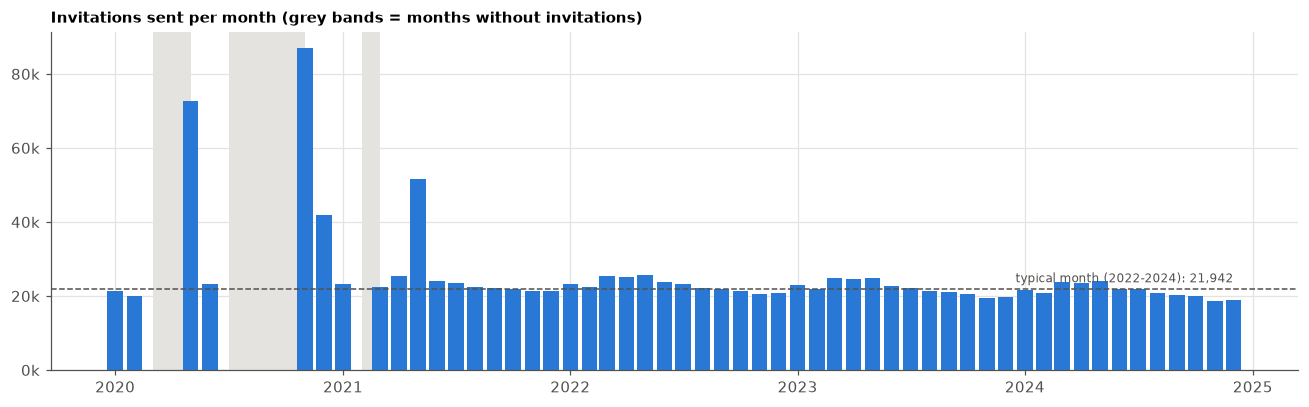

Months without invitations: 2020-03, 2020-04, 2020-07, 2020-08, 2020-09, 2020-10, 2021-02
Catch-up batches (> 2x a typical month): 2020-05 72,750 (3.3x), 2020-11 87,036 (4.0x), 2021-05 51,483 (2.3x)


In [2]:
months = pd.period_range("2020-01", "2024-12", freq="M")
monthly = df.groupby("month").agg(
    n=("SCREENING_12M_FLAG", "size"), r3=("SCREENING_3M_FLAG", "mean"), r12=("SCREENING_12M_FLAG", "mean")
).reindex(months)
normal = monthly.loc[monthly.index.year >= 2022, "n"].median()
x = months.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 3.8))
for gap in monthly.index[monthly.n.isna()]:  # shade the months without invitations
    ax.axvspan(gap.to_timestamp(), (gap + 1).to_timestamp(), color=GRID, lw=0)
ax.bar(x, monthly.n.fillna(0), width=25, color=BLUE)
ax.axhline(normal, color=INK2, lw=1, ls="--")
ax.text(x[-1], normal * 1.08, f"typical month (2022-2024): {normal:,.0f}", ha="right", fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_title("Invitations sent per month (grey bands = months without invitations)")
plt.tight_layout(); plt.show()

gaps = monthly[monthly.n.isna()].index.astype(str).tolist()
big = monthly[monthly.n > 2 * normal]
print("Months without invitations:", ", ".join(gaps))
print("Catch-up batches (> 2x a typical month):",
      ", ".join(f"{m} {int(n):,} ({n / normal:.1f}x)" for m, n in big.n.items()))

## 2. Fewer women came, and they came later

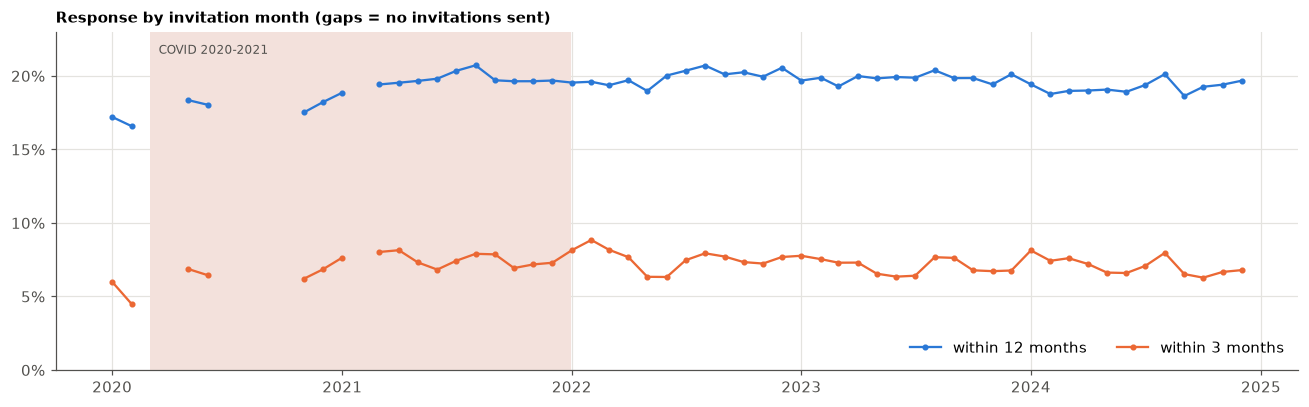

Lowest month: 2020-02, 4.5% within 3 months and 16.6% within 12 months


In [3]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color=SHADE, lw=0)
ax.text(pd.Timestamp("2020-03-15"), 0.215, "COVID 2020-2021", fontsize=8, color=INK2)
ax.plot(x, monthly.r12, color=BLUE, marker="o", ms=3, label="within 12 months")
ax.plot(x, monthly.r3, color=ORANGE, marker="o", ms=3, label="within 3 months")
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.23)
ax.legend(loc="lower right", ncol=2)
ax.set_title("Response by invitation month (gaps = no invitations sent)")
plt.tight_layout(); plt.show()
worst = monthly.r12.idxmin()
print(f"Lowest month: {worst}, {monthly.r3[worst]:.1%} within 3 months and {monthly.r12[worst]:.1%} within 12 months")

In [4]:
yearly = df.groupby("year").agg(
    invitations=("SCREENING_12M_FLAG", "size"),
    within_3m=("SCREENING_3M_FLAG", "mean"),
    within_12m=("SCREENING_12M_FLAG", "mean"),
)
yearly["came within 3m (share of responders)"] = yearly.within_3m / yearly.within_12m
yearly.style.format({"invitations": "{:,}", "within_3m": "{:.1%}", "within_12m": "{:.1%}",
                     "came within 3m (share of responders)": "{:.0%}"})

,invitations,within_3m,within_12m,came within 3m (share of responders)
year,,,,
2020,"266,502",6.4%,17.8%,36%
2021,"279,010",7.5%,19.7%,38%
2022,"275,993",7.6%,19.9%,38%
2023,"266,585",7.1%,19.8%,36%
2024,"256,466",7.1%,19.2%,37%


## 3. Behaviour, not a different mix of women

Each invitation's segment (`segmentation/segments.py`) describes who she is at the invitation date. If 2020 had
the 2021–2024 response rates of its segments, its overall rate would be the *expected* value below.

In [5]:
seg = assign(df)
by_seg = df.pivot_table(index=seg, columns="year", values="SCREENING_12M_FLAG", aggfunc="mean", observed=False)
display(by_seg.style.format("{:.1%}").set_caption("12-month response by segment and year"))

later = df.year >= 2021
rate_later = df.loc[later, "SCREENING_12M_FLAG"].groupby(seg[later]).mean()
y20 = df.year == 2020
expected = seg[y20].map(rate_later).astype(float).mean()
actual = df.loc[y20, "SCREENING_12M_FLAG"].mean()
print(f"2020: actual {actual:.1%}, expected from its segment mix at 2021-2024 rates {expected:.1%} "
      f"-> {(expected - actual) * 100:.1f} percentage points fewer women came")

year,2020,2021,2022,2023,2024
SEGMENT,,,,,
A not due yet,2.2%,2.3%,2.2%,2.6%,2.4%
B first invitation,48.1%,53.5%,54.4%,54.8%,55.1%
"C lapsed screener, gynaecologist",36.2%,41.0%,42.8%,42.5%,43.3%
"D lapsed screener, no gynaecologist",19.6%,23.6%,24.5%,24.4%,24.8%
"E never screened, gynaecologist",20.2%,21.9%,21.5%,21.3%,20.5%
"F never screened, other screening",7.5%,8.9%,9.2%,9.3%,9.3%
"G never screened, healthcare user",5.1%,5.6%,5.8%,6.5%,6.1%
H disconnected,2.0%,1.8%,1.3%,2.7%,2.6%


2020: actual 17.8%, expected from its segment mix at 2021-2024 rates 20.2% -> 2.4 percentage points fewer women came


## 4. The look-back features show a smaller dip

In [6]:
feats = df.groupby("year").agg(
    healthcare_contacts_12m_median=("HEALTHCARE_CONTACT_12M_CNT", "median"),
    gp_prevention_24m=("GP_PREVENTION_24M_CNT", lambda s: (s > 0).mean()),
    gynaecologist_prevention_24m=("GYN_PREVENTION_24M_CNT", lambda s: (s > 0).mean()),
    other_screening_36m=("OTHER_SCREENING_36M_CNT", lambda s: (s > 0).mean()),
    dental_prevention_24m=("DENTAL_PREVENTION_24M_CNT", lambda s: (s > 0).mean()),
    screened_before_5y=("MONTHS_SINCE_LAST_SCREEN", lambda s: s.notna().mean()),
    first_invitation=("FIRST_INVITATION", "mean"),
    mean_age=("AGE_BAND_MEAN", "mean"),
)
feats.style.format(dict.fromkeys(feats.columns, "{:.1%}") | {"healthcare_contacts_12m_median": "{:.0f}", "mean_age": "{:.1f}"})\
    .set_caption("Features by invitation year (shares of invitations with at least one visit)")

,healthcare_contacts_12m_median,gp_prevention_24m,gynaecologist_prevention_24m,other_screening_36m,dental_prevention_24m,screened_before_5y,first_invitation,mean_age
year,,,,,,,,
2020,10,41.0%,35.3%,51.7%,56.6%,19.0%,18.8%,56.0
2021,12,39.3%,36.1%,52.0%,55.4%,19.8%,18.0%,55.9
2022,13,40.9%,36.4%,51.5%,55.3%,18.9%,17.0%,55.8
2023,11,44.1%,37.6%,52.2%,55.2%,17.0%,16.1%,55.6
2024,11,46.2%,38.7%,53.9%,54.9%,15.9%,15.3%,55.8


## 5. The model ranks COVID-period invitations as well as any other year

Gradient boosting (the best model, `training/classifiers`) trained on the train split, which mixes all years. Per
year of the test invitations: ROC AUC, the actual rate and the average predicted probability.

In [7]:
from data import prepare
from gradient_boosting.model import make_model


LABEL = "SCREENING_12M_FLAG"
data, x_split = prepare()
model = make_model(x_split["train"]).fit(x_split["train"], data["train"][LABEL])
test = data["test"].assign(p=model.predict_proba(x_split["test"])[:, 1],
                           year=pd.to_datetime(data["test"].INVITATION_DATE).dt.year)
by_year = pd.DataFrame([
    {"year": y, "test invitations": len(g), "actual": g[LABEL].mean(), "predicted": g.p.mean(),
     "predicted - actual": g.p.mean() - g[LABEL].mean(), "ROC AUC": roc_auc_score(g[LABEL], g.p)}
    for y, g in test.groupby("year")
]).set_index("year")
display(by_year.style.format({"test invitations": "{:,}", "actual": "{:.1%}", "predicted": "{:.1%}",
                              "predicted - actual": lambda v: f"{v * 100:+.1f} pp".replace("-0.0", "0.0").replace("+0.0", "0.0"), "ROC AUC": "{:.3f}"}))

with_year = {k: v.assign(YEAR=pd.to_datetime(data[k].INVITATION_DATE).dt.year) for k, v in x_split.items()}
model_y = make_model(with_year["train"]).fit(with_year["train"], data["train"][LABEL])
auc = roc_auc_score(test[LABEL], test.p)
auc_y = roc_auc_score(data["test"][LABEL], model_y.predict_proba(with_year["test"])[:, 1])
print(f"Test ROC AUC without the year: {auc:.4f}, with the year as a feature: {auc_y:.4f} ({auc_y - auc:+.4f})")

,test invitations,actual,predicted,predicted - actual,ROC AUC
year,,,,,
2020,"40,091",17.9%,18.7%,+0.8 pp,0.842
2021,"41,821",19.7%,19.7%,0.0 pp,0.848
2022,"41,392",19.7%,19.7%,0.0 pp,0.844
2023,"40,015",20.1%,19.4%,-0.7 pp,0.834
2024,"38,532",19.0%,18.8%,-0.2 pp,0.837


Test ROC AUC without the year: 0.8412, with the year as a feature: 0.8419 (+0.0007)


## 6. Takeaways

- **Invitations were paused and sent in catch-up batches.** No letters in March–April 2020, July–October 2020 and
  February 2021, then catch-up batches in May 2020 (3.3× a typical month), November 2020 (4.0×) and May 2021 (2.3×).
- **Fewer women came, and later.** In 2020, 17.8 % were screened within 12 months vs. 19.2–19.9 % in 2021–2024, and
  only 6.4 % within 3 months (7.1–7.6 % later). The worst month is February 2020, invited just before the first
  lockdown: 4.5 % within 3 months, 16.6 % within 12.
- **Behaviour, not a different mix of women.** With 2021–2024 rates, 2020's mix of women would have given 20.2 %;
  the actual 17.8 % means about 2.4 percentage points fewer women came. The drop hit the women who usually come most:
  first invitations (48 % vs. 54–55 %) and lapsed regular screeners (36 % vs. 41–43 %; 20 % vs. 24–25 %). Women
  who never screen were barely affected. The likely reason: limited screening capacity and postponed visits.
- **Look-back features show a smaller dip.** For invitations whose look-back window covers the pandemic, fewer
  women had a GP prevention visit (39–41 % in 2021–2022 vs. 44–46 % in 2023–2024), and 2020 invitations have the
  lowest median of healthcare contacts (10 vs. 11–13).
- **The model is barely affected.** It ranks 2020 invitations as well as other years (ROC AUC 0.842), but its
  probabilities are 0.8 percentage points too high there, since it does not know about the pandemic. Adding the year
  as a feature improves the overall ROC AUC by only +0.0007.

**Implications.** No change to the model is needed: COVID shifted the level of response, not who responds.
Where exact probabilities or expected rates matter (capacity planning, the experiment's baseline rates), use
2021–2024, which is closer to what a future pilot will face.